Центральность по вершинам:
Вершина  0: 0.00000
Вершина  1: 0.00000
Вершина  2: 0.00000
Вершина  3: 0.00001
Вершина  4: 0.00004
Вершина  5: 0.00014
Вершина  6: 0.00054
Вершина  7: 0.00207
Вершина  8: 0.00798
Вершина  9: 0.03069
Вершина 10: 0.11806
Вершина 11: 0.45420
Вершина 12: 0.43109
Вершина 13: 0.43109
Вершина 14: 0.43109
Вершина 15: 0.45420
Вершина 16: 0.11806
Вершина 17: 0.03069
Вершина 18: 0.00798
Вершина 19: 0.00207
Вершина 20: 0.00054
Вершина 21: 0.00014
Вершина 22: 0.00004
Вершина 23: 0.00001
Вершина 24: 0.00000
Вершина 25: 0.00000

Изображения сохранены в файлы:
- centrality_profile.png (профиль центральности)
- graph_visualization.png (визуализация графа)


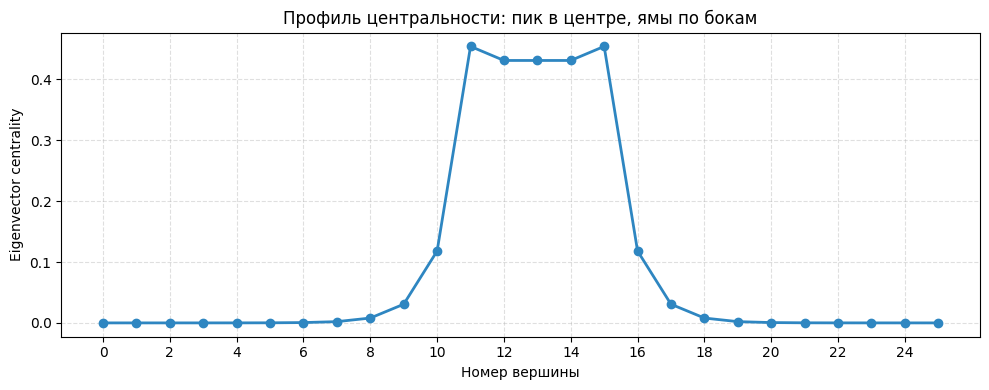

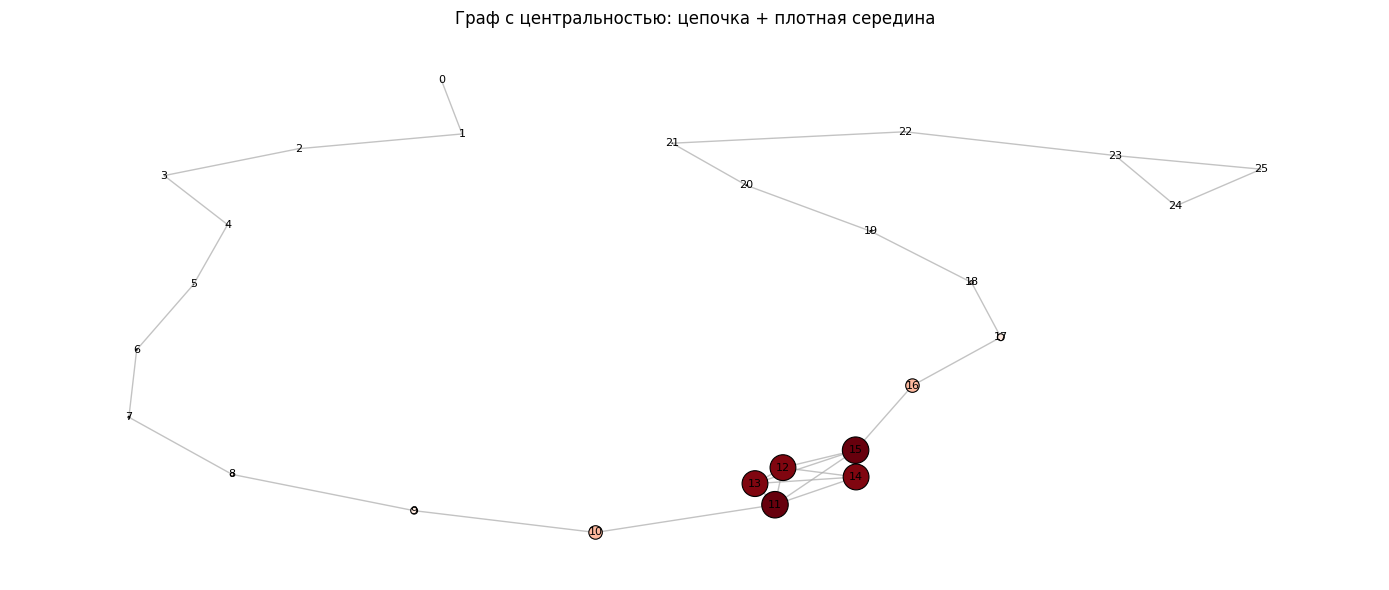

In [1]:
import networkx as nx
import matplotlib.pyplot as plt

# Параметры графа
n = 26
center_nodes = [11, 12, 13, 14, 15]  # центральные вершины для пика

# Создание графа
G = nx.Graph()
G.add_nodes_from(range(n))

# Базовая цепочка (обеспечивает связность)
for i in range(n - 1):
    G.add_edge(i, i + 1)

# Создание плотной зоны в центре (формирует пик)
for i in range(len(center_nodes)):
    for j in range(i + 1, len(center_nodes)):
        G.add_edge(center_nodes[i], center_nodes[j])

# Дополнительное ребро для подъёма в конце
G.add_edge(25, 23)

# Вычисление центральности
eigen_centrality = nx.eigenvector_centrality(G, max_iter=1000, tol=1e-8)
centralities = [eigen_centrality[i] for i in range(n)]

# Визуализация профиля центральности
plt.figure(figsize=(10, 4))
plt.plot(range(n), centralities, marker="o", linestyle="-", color="#2E86C1", linewidth=2, markersize=6)
plt.xticks(range(0, n, 2))
plt.xlabel("Номер вершины")
plt.ylabel("Eigenvector centrality")
plt.title("Профиль центральности: пик в центре, ямы по бокам")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()

# Сохранение профиля
plt.savefig("centrality_profile.png", dpi=300, bbox_inches="tight")

# Визуализация самого графа
plt.figure(figsize=(14, 6))
pos = nx.spring_layout(G, seed=42, k=0.35, iterations=50)

# Настройка отображения узлов
sizes = [c * 800 for c in centralities]
colors = centralities

nx.draw_networkx_edges(G, pos, edge_color="#aaaaaa", alpha=0.7)
nx.draw_networkx_nodes(
    G, pos,
    node_size=sizes,
    node_color=colors,
    cmap=plt.cm.Reds,
    edgecolors="black",
    linewidths=0.8
)
nx.draw_networkx_labels(G, pos, font_size=8, font_color="black")

plt.title("Граф с центральностью: цепочка + плотная середина")
plt.axis("off")
plt.tight_layout()

# Сохранение изображения графа
plt.savefig("graph_visualization.png", dpi=300, bbox_inches="tight")

# Вывод результатов
print("Центральность по вершинам:")
for i, c in enumerate(centralities):
    print(f"Вершина {i:2d}: {c:.5f}")

print("\nИзображения сохранены в файлы:")
print("- centrality_profile.png (профиль центральности)")
print("- graph_visualization.png (визуализация графа)")
